# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "ricardo_72", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

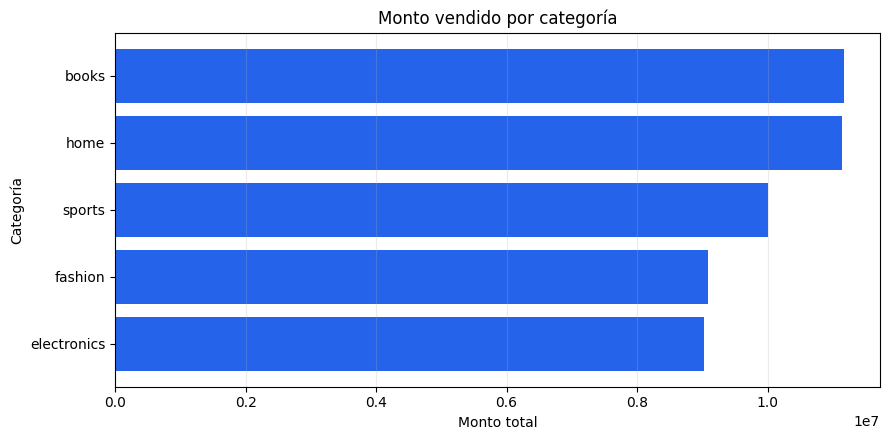

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

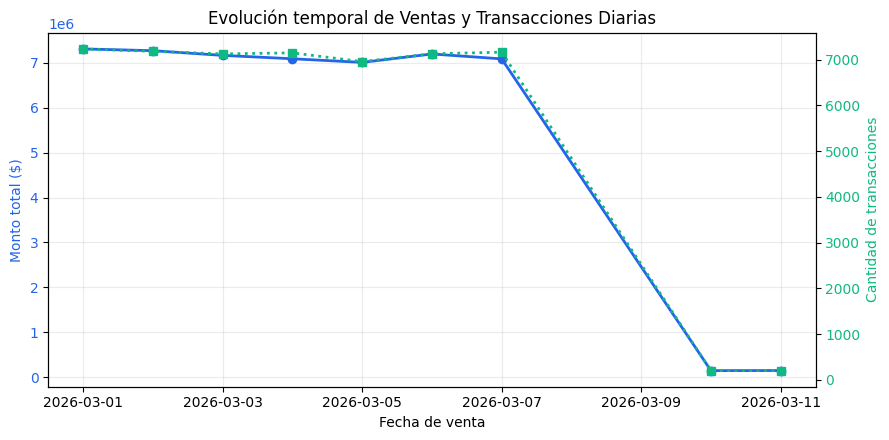

Respuesta: El día con mayor monto vendido fue el 2026-03-01 ($7,310,840.77) y el día con mayor cantidad de transacciones fue el 2026-03-01 (7,236). Ambos máximos coinciden. Esto implica que el ticket promedio de ese día ($1,010.34) se mantuvo estable y proporcional al volumen, traccionado por una afluencia masiva de clientes.


In [0]:
# Tu solución. Agregá por sale_date antes de convertir el resultado a Pandas.
# Incluí título, ejes, unidades y una respuesta escrita.
import matplotlib.pyplot as plt

# 1. Agregación en Spark usando las columnas reales de tu esquema
daily_metrics = (spark.table(daily)
    .groupBy("sale_date")
    .agg(
        F.sum("total_amount").alias("monto_vendido"),
        F.sum("transaction_count").alias("cant_transacciones")
    )
    .withColumn("ticket_promedio", F.col("monto_vendido") / F.col("cant_transacciones"))
    .orderBy("sale_date"))

# 2. Conversión a Pandas para la visualización temporal
plot_data = daily_metrics.toPandas()

# 3. Construcción del gráfico temporal con doble eje para mantener las unidades intactas
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color_monto = "#2563eb"
ax1.plot(plot_data["sale_date"], plot_data["monto_vendido"], color=color_monto, marker='o', linewidth=2)
ax1.set_title("Evolución temporal de Ventas y Transacciones Diarias")
ax1.set_xlabel("Fecha de venta")
ax1.set_ylabel("Monto total ($)", color=color_monto)
ax1.tick_params(axis='y', labelcolor=color_monto)
ax1.grid(axis="both", alpha=0.25)

# Segundo eje Y independiente para transacciones
ax2 = ax1.twinx()
color_trans = "#10b981"
ax2.plot(plot_data["sale_date"], plot_data["cant_transacciones"], color=color_trans, marker='s', linewidth=2, linestyle=':')
ax2.set_ylabel("Cantidad de transacciones", color=color_trans)
ax2.tick_params(axis='y', labelcolor=color_trans)

fig.tight_layout()
plt.show()

# 4. Búsqueda de máximos para formular la respuesta automática
max_monto_row = plot_data.loc[plot_data["monto_vendido"].idxmax()]
max_trans_row = plot_data.loc[plot_data["cant_transacciones"].idxmax()]

fecha_monto = str(max_monto_row["sale_date"])
fecha_trans = str(max_trans_row["sale_date"])

if fecha_monto == fecha_trans:
    implicancia = f"Ambos máximos coinciden. Esto implica que el ticket promedio de ese día (${max_monto_row['ticket_promedio']:,.2f}) se mantuvo estable y proporcional al volumen, traccionado por una afluencia masiva de clientes."
else:
    implicancia = f"Los máximos NO coinciden. El mayor monto fue el {fecha_monto} y la mayor cantidad de transacciones fue el {fecha_trans}. Esto implica que el día de mayor facturación tuvo un ticket promedio inusualmente alto (${max_monto_row['ticket_promedio']:,.2f}), impulsado por compras individuales de gran valor en lugar de un alto volumen de clientes."

print(f"Respuesta: El día con mayor monto vendido fue el {fecha_monto} (${max_monto_row['monto_vendido']:,.2f}) y el día con mayor cantidad de transacciones fue el {fecha_trans} ({max_trans_row['cant_transacciones']:,}). {implicancia}")


## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

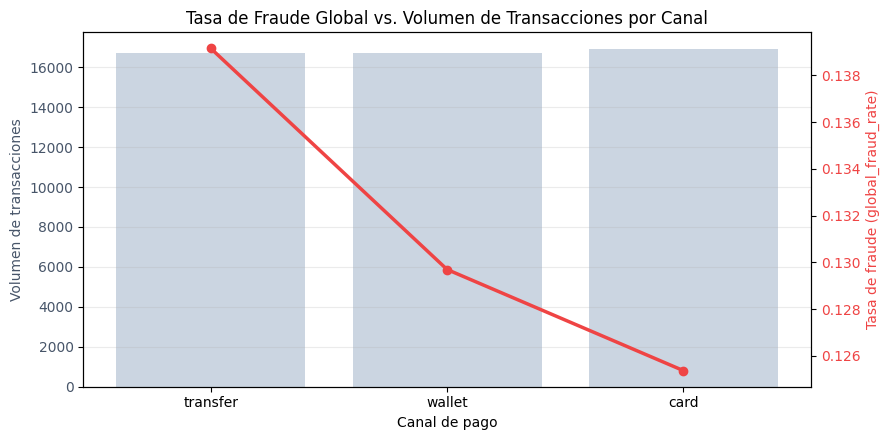

Respuesta: El canal de pago que presenta la mayor tasa de fraude es transfer con una tasa global de 0.1391. Esta conclusión NO SE SOSTIENE necesariamente al considerar el volumen. El canal con mayor tasa es transfer (0.1391), pero el canal que concentra el mayor volumen de transacciones es card (16,902 transacciones). Esto demuestra que el fraude está proporcionalmente más concentrado en un canal de menor uso.


In [0]:
# Tu solución. Recalculá la tasa global como suma(fraud_transactions) / suma(transaction_count).
# Evitá promediar directamente fraud_rate entre grupos.

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# 1. Agregación en Spark calculando la tasa global correctamente
channel_fraud = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("fraud_transactions").alias("total_fraud"),
        F.sum("transaction_count").alias("total_transactions")
    )
    .withColumn("global_fraud_rate", F.col("total_fraud") / F.col("total_transactions"))
    .orderBy(F.desc("global_fraud_rate")))

# 2. Conversión a Pandas para graficar
plot_data = channel_fraud.toPandas()

# 3. Construcción del gráfico combinado (Barras para Volumen, Línea para Tasa)
fig, ax1 = plt.subplots(figsize=(9, 4.5))

# Eje principal: Volumen de transacciones (Barras)
color_vol = "#cbd5e1"  # Gris claro para dar protagonismo a la tasa
ax1.bar(plot_data["payment_channel"], plot_data["total_transactions"], color=color_vol, label="Transacciones Totales")
ax1.set_title("Tasa de Fraude Global vs. Volumen de Transacciones por Canal")
ax1.set_xlabel("Canal de pago")
ax1.set_ylabel("Volumen de transacciones", color="#475569")
ax1.tick_params(axis='y', labelcolor="#475569")
ax1.grid(axis="y", alpha=0.25)

# Eje secundario: Tasa de fraude (Línea)
ax2 = ax1.twinx()
color_tasa = "#ef4444"  # Rojo para resaltar el riesgo de fraude
ax2.plot(plot_data["payment_channel"], plot_data["global_fraud_rate"], color=color_tasa, marker='o', linewidth=2.5, label="Tasa de Fraude")
# Formatear el eje de la tasa como porcentaje (multiplicar por 100 si querés mostrar %, o dejar en formato decimal)
ax2.set_ylabel("Tasa de fraude (global_fraud_rate)", color=color_tasa)
ax2.tick_params(axis='y', labelcolor=color_tasa)

fig.tight_layout()
plt.show()

# 4. Extracción de líderes para armar la respuesta analítica
highest_rate_row = plot_data.iloc[0]
highest_vol_row = plot_data.loc[plot_data["total_transactions"].idxmax()]

canal_mas_fraude = highest_rate_row["payment_channel"]
canal_mas_vol = highest_vol_row["payment_channel"]
sostiene_conclusion = (canal_mas_fraude == canal_mas_vol)

if sostiene_conclusion:
    analisis_volumen = f"Esta conclusión SE SOSTIENE al considerar el volumen, ya que este canal también concentra la mayor cantidad de operaciones totales ({highest_vol_row['total_transactions']:,} transacciones), representando un riesgo crítico tanto en tasa como en exposición absoluta."
else:
    analisis_volumen = f"Esta conclusión NO SE SOSTIENE necesariamente al considerar el volumen. El canal con mayor tasa es {canal_mas_fraude} ({highest_rate_row['global_fraud_rate']:.4f}), pero el canal que concentra el mayor volumen de transacciones es {canal_mas_vol} ({highest_vol_row['total_transactions']:,} transacciones). Esto demuestra que el fraude está proporcionalmente más concentrado en un canal de menor uso."

print(f"Respuesta: El canal de pago que presenta la mayor tasa de fraude es {canal_mas_fraude} con una tasa global de {highest_rate_row['global_fraud_rate']:.4f}. {analisis_volumen}")


## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

In [0]:
# Tu solución. Algunas opciones: mapa de calor o barras agrupadas.
# La conclusión debe mencionar tanto el máximo global como las diferencias entre países.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

In [0]:
# Tu solución. Calculá total = accepted_transactions + rejected_transactions.
# Un gráfico de barras apiladas al 100% puede facilitar la comparación de proporciones.

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.